In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import random
from keras import models,layers
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

In [2]:
x_train=np.load("cifar-10.npz/x_train.npy")
y_train=np.load("cifar-10.npz/y_train.npy")
x_test=np.load("cifar-10.npz/x_test.npy")
y_test=np.load("cifar-10.npz/y_test.npy")

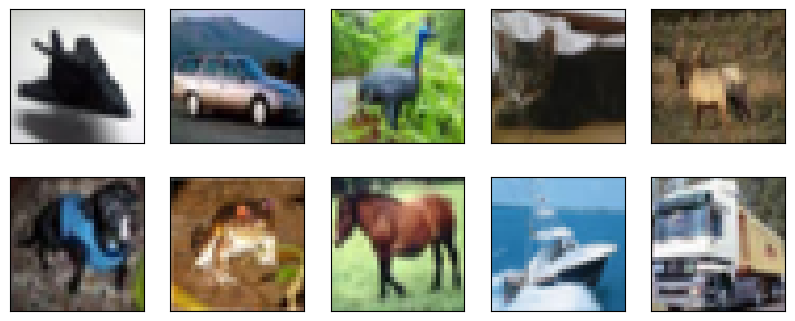

In [3]:
unique_labels = np.unique(y_train)

plt.figure(figsize=(10, 4))
for i in range(len(unique_labels)):
    idx = np.where(y_train == unique_labels[i])[0][0]
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[idx])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
plt.show()

In [4]:
max_pixel_value = x_train.max()
x_train = x_train.astype("float32") / max_pixel_value
x_test = x_test.astype("float32") / max_pixel_value

In [8]:
model = models.Sequential([
    layers.Input(shape=(32, 32,3)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'), 
    layers.Dense(128, activation='relu'), 
    layers.Dense(64, activation='relu'),  
    layers.Dense(10, activation='softmax') 
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │         786,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 828,490 (3.16 MB)

 Trainable params: 828,490 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)
history = model.fit(
    x_train, y_train,
    epochs=50,
    validation_data=(x_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.3134 - loss: 1.8842 - val_accuracy: 0.3534 - val_loss: 1.7575
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - accuracy: 0.3943 - loss: 1.6877 - val_accuracy: 0.4099 - val_loss: 1.6512
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - accuracy: 0.4237 - loss: 1.6085 - val_accuracy: 0.4134 - val_loss: 1.6278
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.4421 - loss: 1.5565 - val_accuracy: 0.4466 - val_loss: 1.5400
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.4556 - loss: 1.5209 - val_accuracy: 0.4421 - val_loss: 1.5630
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.4672 - loss: 1.4872 - val_accuracy: 0.4701 - val_loss: 1.4806
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.4743 - loss: 1.4624 - val_accuracy: 0.4727 - val_loss: 1.4617
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.4839 -

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)

In [ ]:
n = random.randint(0, len(x_test)-1)
plt.imshow(x_test[n])
predicted_values = model.predict(x_test, verbose=1)
predicted_class = np.argmax(predicted_values[n])
actual_class=y_test[n]
print(f"Handwritten number in the displayed image (index {n}) is: {predicted_class}")

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], marker='o')
plt.plot(history.history['val_accuracy'], marker='s')
plt.ylabel('Accuracy', fontsize=12)
plt.xlabel('Epoch', fontsize=12)
plt.legend(['Train', 'Validation'], loc='lower right')
plt.grid(True)
plt.show()